# 04 – Substructure search and molecular similarity with RDKit

**Goal:** find functional groups with SMARTS, understand what a Morgan fingerprint encodes, compare molecules with the Tanimoto similarity, and run a similarity search on the ESOL dataset. **Time:** about 2 hours, including exercises.

1. Substructure search with SMARTS
2. Morgan fingerprints
3. Tanimoto similarity
4. Similarity search

There's one exercise per section, plus a short final exercise.

## Setup

In [1]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator

- **`DataStructs`** contains the fingerprint data types and the similarity functions.
- **`rdFingerprintGenerator`** is RDKit's current interface for making fingerprints. Older tutorials use `AllChem.GetMorganFingerprintAsBitVect`, which is deprecated.

In [2]:
df = pd.read_csv("data/delaney-processed.csv")
df = df.rename(columns={
    "Compound ID": "name",
    "measured log solubility in mols per litre": "logS",
})
df = df[["name", "smiles", "logS"]].copy()
df["name"] = df["name"].str.strip()
df["smiles"] = df["smiles"].str.strip()
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)

print(len(df), df["mol"].isna().sum())

1128 0


- Only the three columns needed here are kept. `.copy()` makes the selection an independent DataFrame, so adding columns to it later is safe.
- The **names** have trailing whitespace too (`"Benzene "`), so they're stripped like the SMILES. Without that, `df["name"] == "Benzene"` finds nothing.
- All 1,128 SMILES parse (0 `None`).

A small helper to get a molecule by its name, used throughout the notebook:

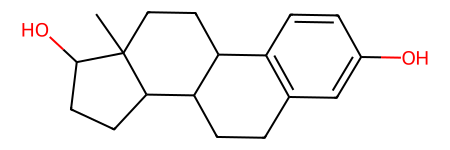

In [3]:
def mol_by_name(name):
    """Return the RDKit Mol of the ESOL compound with this name."""
    return df.loc[df["name"] == name, "mol"].iloc[0]

mol_by_name("Estradiol")

`.iloc[0]` takes the first (here: the only) element of the filtered Series. Without it you'd get a Series of length 1 instead of the `Mol` itself.

## 1. Substructure search with SMARTS

SMILES describes a **molecule**. SMARTS describes a **pattern**. Every SMILES is valid SMARTS, but SMARTS adds queries for atoms and bonds:

| SMARTS | Matches |
|---|---|
| `C` / `c` | aliphatic / aromatic carbon |
| `[#6]` | any carbon, aliphatic or aromatic (atomic number 6) |
| `[F,Cl,Br,I]` | any one of the listed atoms (`,` = OR) |
| `[CX4]` | carbon with 4 connections, H included: sp³ C |
| `[CX3]=O` | carbon with 3 connections, double-bonded to O: carbonyl C |
| `[OX2H]` | O with 2 connections, one of them H: hydroxyl O |
| `[!#1]`, `[C;R]` | `!` = NOT; `;` = AND (`R` = in a ring) |
| `~` | any bond |

- **`X`** counts all connections, including implicit hydrogens. **`H`** counts attached hydrogens. **`D`** counts explicit (heavy-atom) neighbors.
- A bond between atoms written next to each other is single or aromatic, as in SMILES.

In [4]:
patterns = {
    "aromatic halide": Chem.MolFromSmarts("c[F,Cl,Br,I]"),
    "carboxylic acid": Chem.MolFromSmarts("[CX3](=O)[OX2H]"),
    "alcohol": Chem.MolFromSmarts("[CX4][OX2H]"),
}

for group, patt in patterns.items():
    hits = df["mol"].apply(lambda mol: mol.HasSubstructMatch(patt))
    print(f"{group}: {hits.sum()}")

aromatic halide: 211
carboxylic acid: 0
alcohol: 154


- `Chem.MolFromSmarts` turns a SMARTS string into a query molecule. Parse it **once**, outside the loop over molecules.
- `mol.HasSubstructMatch(patt)` returns `True` or `False`.
- `apply` passes only one argument, the molecule. The `lambda` adds the second one, `patt`.
- `dict.items()` gives (key, value) pairs, unpacked into `group, patt`.

**Zero carboxylic acids.** Before you believe a count like that, test the pattern on molecules where you know the answer:

In [5]:
test_smiles = {
    "acetic acid": "CC(=O)O",
    "benzoic acid": "OC(=O)c1ccccc1",
    "methyl acetate": "CC(=O)OC",
    "acetamide": "CC(N)=O",
}

for name, smi in test_smiles.items():
    mol = Chem.MolFromSmiles(smi)
    print(f"{name}: {mol.HasSubstructMatch(patterns['carboxylic acid'])}")

acetic acid: True
benzoic acid: True
methyl acetate: False
acetamide: False


The pattern matches both acids and rejects the ester and the amide. So ESOL simply contains **no carboxylic acids**, which is worth knowing before you train a solubility model on it. Acids ionize in water, so their solubility depends strongly on pH. A model trained on ESOL hasn't seen that behavior.

The alcohol pattern `[CX4][OX2H]` requires an sp³ carbon, so it excludes phenols, which a chemist would also treat separately (pKa ≈ 10 vs ≈ 16). Estradiol has one of each:

In [6]:
phenol_patt = Chem.MolFromSmarts("c[OX2H]")
estradiol = mol_by_name("Estradiol")

print(estradiol.GetSubstructMatches(patterns["alcohol"]))
print(estradiol.GetSubstructMatches(phenol_patt))

((18, 19),)
((10, 11),)


`GetSubstructMatches` returns a tuple of matches. Each match is a tuple of atom indices, in the order of the atoms in the SMARTS: (carbon, oxygen). `GetSubstructMatch` (singular) returns only the first match.

To highlight **all** matches in a drawing, the matches have to be flattened into one list of atom indices:

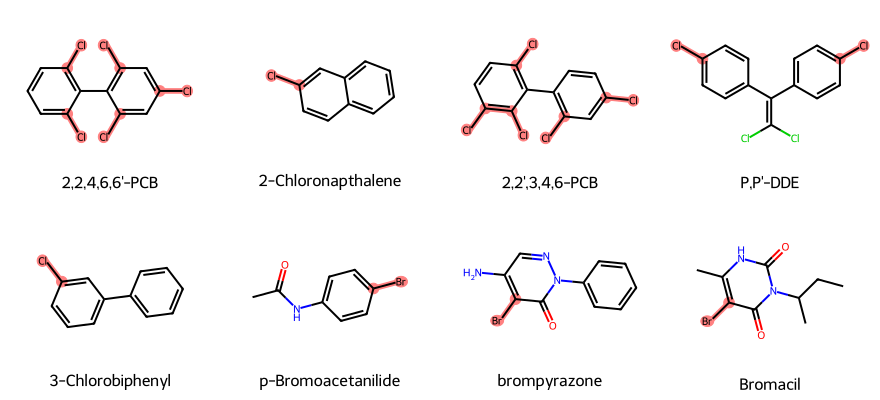

In [7]:
def matched_atoms(mol, patt):
    """All atom indices that are part of any match of patt in mol."""
    return [idx for match in mol.GetSubstructMatches(patt) for idx in match]

is_ar_halide = df["mol"].apply(lambda mol: mol.HasSubstructMatch(patterns["aromatic halide"]))
sample = df[is_ar_halide].head(8)

Draw.MolsToGridImage(
    list(sample["mol"]),
    legends=list(sample["name"]),
    highlightAtomLists=[matched_atoms(mol, patterns["aromatic halide"]) for mol in sample["mol"]],
    molsPerRow=4,
    subImgSize=(220, 200),
)

- A list comprehension with two `for` clauses reads like two nested loops, outer first: for each `match`, for each `idx` in that match.
- `highlightAtomLists` takes one list of atom indices per molecule.

### Exercise 1

1. Write a SMARTS pattern for an **ester** and count the esters in ESOL.
2. Test it on methyl acetate `CC(=O)OC` (should match), acetic acid `CC(=O)O` (should not), γ-butyrolactone `O=C1CCCO1` and carbaryl `CNC(=O)Oc1cccc2ccccc12` (a carbamate). Decide whether a lactone and a carbamate *should* count as esters for your purpose, and adjust the pattern if needed.
3. Draw the first 8 ESOL hits with the ester atoms highlighted.

ester: 105
methyl acrylate: True
acetic acid: False
gamma-butyrolactone: True
carbaryl: False
methyl benzoate: True
ethyl formate: True
N-methyl carbamate: False
methyl carbamate: False
dimethyl carbonate: False


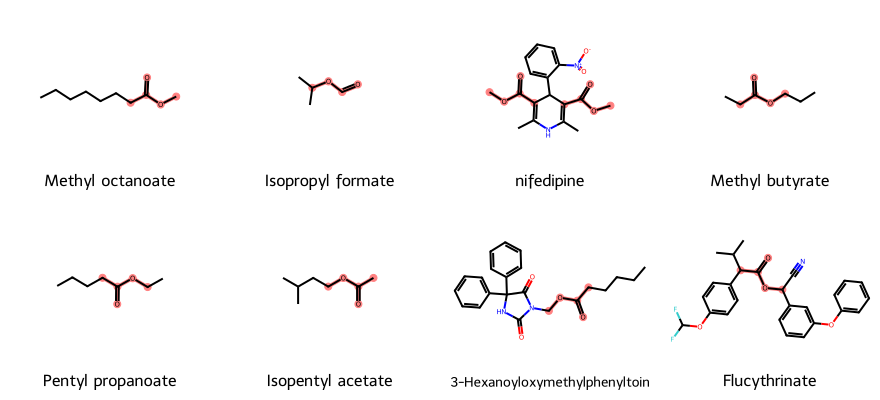

In [8]:
# Exercise 1: your code here
ester_patt1 = Chem.MolFromSmarts("[C,c][CX3](=O)[OX2][CX4]") # ester pattern and not carbamate
ester_patt2 = Chem.MolFromSmarts("[CX3H](=O)[OX2][CX4]") # formate pattern

ester_hits = df["mol"].apply(lambda mol: mol.HasSubstructMatch(ester_patt1) or mol.HasSubstructMatch(ester_patt2))
print(f"ester: {ester_hits.sum()}")

test_ester = {
    "methyl acrylate": "C=CC(=O)OC",
    "acetic acid": "CC(=O)O",
    "gamma-butyrolactone": "O=C1CCCO1",
    "carbaryl": "CNC(=O)Oc1cccc2ccccc12",
    "methyl benzoate": "COC(=O)c1ccccc1",
    "ethyl formate": "CCOC=O",
    "N-methyl carbamate": "CNC(=O)OC",
    "methyl carbamate": "COC(N)=O",
    "dimethyl carbonate": "COC(=O)OC",
}

for name, smi in test_ester.items():
    mol = Chem.MolFromSmiles(smi)
    print(f"{name}: {mol.HasSubstructMatch(ester_patt1) or mol.HasSubstructMatch(ester_patt2)}")

sample_ester = df[ester_hits].head(8)

Draw.MolsToGridImage(
    list(sample_ester["mol"]),
    legends=list(sample_ester["name"]),
    highlightAtomLists=[matched_atoms(mol, ester_patt1) + matched_atoms(mol, ester_patt2) for mol in sample_ester["mol"]],
    molsPerRow=4,
    subImgSize=(220, 200),
)

I excluded carbamates but included the lactones. Lactones are cyclic esters, I know the reactivity is different but in this exercise, I want to treat them in the same group. 
In this dataset, we are looking at the solubility of the compounds, therefore lactones are similar to esters because they have the same amount of HBD and HBA. For carbamates however, things are different because an NH is an added HBD.

I had to use two patterns because otherwise formates are not included because Hs are implicit. 

I also learned three SMARTS lessons: 1. Everything inside one pair of brackets describes one atom, so [CX3;!N] doesn't exclude a neighboring N. 2. H inside brackets is an H count, so [C,H] also matches an N–H. 3. C is aliphatic carbon only, while [C,c] matches any carbon.

## 2. Morgan fingerprints

A **Morgan fingerprint** (ECFP) is a vector of 2048 bits. Each bit that is on stands for one **atom environment**: a central atom plus all atoms up to *r* bonds away, for r = 0, 1 and 2. We start with butan-1-ol, drawn with its atom indices:

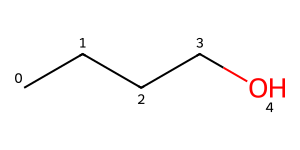

In [9]:
butanol = Chem.MolFromSmiles("CCCCO")

labeled = Chem.Mol(butanol)
for atom in labeled.GetAtoms():
    atom.SetProp("atomNote", str(atom.GetIdx()))

Draw.MolToImage(labeled, size=(300, 150))

`Chem.Mol(mol)` makes a copy, so the index labels don't appear in later drawings of `butanol`. Now grow the environment around C2, one bond per radius:

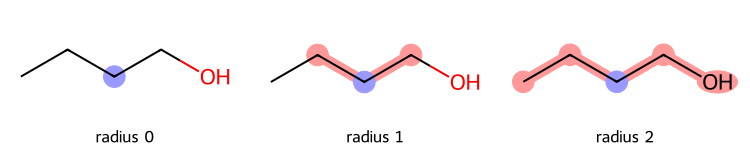

In [10]:
def environment(mol, center, radius):
    """Atom and bond indices of the environment of given radius around center."""
    bonds = list(Chem.FindAtomEnvironmentOfRadiusN(mol, radius, center))
    atoms = {center}
    for bond_idx in bonds:
        bond = mol.GetBondWithIdx(bond_idx)
        atoms |= {bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()}
    return sorted(atoms), bonds

center = 2
envs = [environment(butanol, center, radius) for radius in [0, 1, 2]]
BLUE, RED = (0.6, 0.6, 1.0), (1.0, 0.6, 0.6)

Draw.MolsToGridImage(
    [butanol] * 3,
    legends=["radius 0", "radius 1", "radius 2"],
    highlightAtomLists=[atoms for atoms, bonds in envs],
    highlightBondLists=[bonds for atoms, bonds in envs],
    highlightAtomColors=[{a: BLUE if a == center else RED for a in atoms} for atoms, bonds in envs],
    highlightBondColors=[{b: RED for b in bonds} for atoms, bonds in envs],
    molsPerRow=3,
    subImgSize=(250, 150),
)

- `FindAtomEnvironmentOfRadiusN` returns only **bond** indices, so the loop collects the two atoms of each bond. `|=` adds them to the set `atoms`.
- `[butanol] * 3` is a list with the same molecule three times, one panel per radius.
- `{a: ... for a in atoms}` is a dict comprehension: it builds a dict of atom index → RGB color, blue for the center and red for the rest.

**Look at:** the central atom (blue) stays the same, and each radius adds the next shell of neighbors. At radius 2, C2 already covers the whole molecule.

The algorithm does this for **every** heavy atom, turns each environment into an integer identifier, and folds that into one of the 2048 bit positions. Radius 2 is the usual choice, called **ECFP4** (4 = diameter). An `AdditionalOutput` object records which environment set which bit:

In [11]:
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def fp_with_info(mol):
    """Morgan fingerprint of mol and its bit info map {bit: ((atom, radius), ...)}."""
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    fp = morgan_gen.GetFingerprint(mol, additionalOutput=ao)
    return fp, ao.GetBitInfoMap()

fp, bit_info = fp_with_info(butanol)

print(fp.GetNumOnBits(), "of", fp.GetNumBits(), "bits are on")
for bit, envs in sorted(bit_info.items()):
    print(bit, envs)

11 of 2048 bits are on
80 ((1, 0), (2, 0), (3, 0))
222 ((4, 1),)
294 ((0, 1),)
473 ((3, 1),)
591 ((1, 2),)
794 ((1, 1),)
807 ((4, 0),)
1057 ((0, 0),)
1082 ((2, 2),)
1130 ((3, 2),)
1911 ((2, 1),)


- The **generator** holds the settings and is created once, then reused for every molecule.
- Each line is: bit position, then the `(central atom, radius)` pairs that set it.

**Look at bit 80:** atoms 1, 2 and 3 are all CH₂ with two heavy neighbors, so at radius 0 they are the same environment and set one bit. That's why 5 atoms × 3 radii give only 11 bits. The pictures show each bit's fragment:

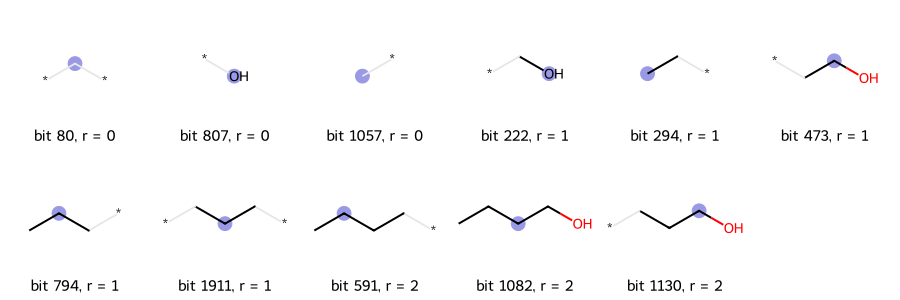

In [12]:
bits = sorted(bit_info, key=lambda bit: bit_info[bit][0][1])

Draw.DrawMorganBits(
    [(butanol, bit, bit_info) for bit in bits],
    legends=[f"bit {bit}, r = {bit_info[bit][0][1]}" for bit in bits],
    molsPerRow=6,
    subImgSize=(150, 150),
)

**Blue** is the central atom. Grey bonds ending in `*` show where the fragment attaches to the rest of the molecule; they aren't part of it. A bit only says "this fragment occurs **somewhere** in the molecule", not where or how often.

### Two molecules, bit by bit

Pentan-1-ol has one more CH₂. Each atom is coloured **green** if every environment centred on it also occurs in the other molecule, and **red** if it sets a bit that the other molecule doesn't have:

butan-1-ol: 11 bits, pentan-1-ol: 12 bits, shared: 10


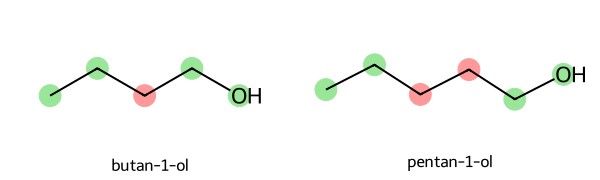

In [13]:
pentanol = Chem.MolFromSmiles("CCCCCO")

fp_a, info_a = fp_with_info(butanol)
fp_b, info_b = fp_with_info(pentanol)
shared = set(info_a) & set(info_b)

GREEN, RED = (0.6, 0.9, 0.6), (1.0, 0.6, 0.6)

def shared_colors(bit_info, shared):
    """Atom colors: RED if an environment centred on the atom is not shared, else GREEN."""
    colors = {}
    for bit, envs in bit_info.items():
        for atom_idx, radius in envs:
            if bit not in shared:
                colors[atom_idx] = RED
            elif atom_idx not in colors:
                colors[atom_idx] = GREEN
    return colors

colors = [shared_colors(info_a, shared), shared_colors(info_b, shared)]

print(f"butan-1-ol: {len(info_a)} bits, pentan-1-ol: {len(info_b)} bits, shared: {len(shared)}")
Draw.MolsToGridImage(
    [butanol, pentanol],
    legends=["butan-1-ol", "pentan-1-ol"],
    highlightAtomLists=[list(c) for c in colors],
    highlightAtomColors=colors,
    highlightBondLists=[[], []],
    molsPerRow=2,
    subImgSize=(300, 180),
)

- `set(info_a)` gives the set of bit positions (the dict keys), and `&` keeps the ones present in both.
- `elif atom_idx not in colors` makes sure a red atom is never turned back to green by a later, shared bit.

Only the middle carbons are red: their radius-2 environments reach far enough along the chain to notice the extra CH₂, while the environments near the chain ends look the same in both molecules. The **Tanimoto similarity** is the number of shared bits divided by the number of bits on in either molecule, so here 10 / (11 + 12 − 10):

In [14]:
print(len(shared) / len(set(info_a) | set(info_b)))
print(DataStructs.TanimotoSimilarity(fp_a, fp_b))

0.7692307692307693
0.7692307692307693


### Exercise 2

Chlorobenzene and bromobenzene are both in ESOL.

1. Compute both fingerprints with `fp_with_info`. How many bits are on in each, and why so few for 7 heavy atoms?
2. Draw the shared bits, then the bits that only chlorobenzene has. Which environments are too far from the halogen to "see" it?

In [15]:
# Exercise 2: your code here
chlorobenzene = mol_by_name("Chlorobenzene")
bromobenzene = mol_by_name("Bromobenzene")

fp_chlorobenzene, info_chlorobenzene = fp_with_info(chlorobenzene)
fp_bromobenzene, info_bromobenzene = fp_with_info(bromobenzene)

print(f"Chlorobenzene: {len(info_chlorobenzene)} bits, Bromobenzene: {len(info_bromobenzene)} bits")

Chlorobenzene: 11 bits, Bromobenzene: 11 bits


There are only 11 bits on for both molecules. The molecules are symmetrical, therefore the environments for some atoms are identical. C2/C6 (ortho), C3/C5 (meta) are identical.

For r = 0: 1 Cl +1 arom CH + 1 arom Cq. -> 3

For r = 1: meta and para are in the same bit (because both are CH between 2 CHs). -> 1 ipso + 1 ortho + 1meta and para + 1 Cl = 4

For r = 2: ortho pair, meta pair. -> 1 ipso, 1 meta + 1ortho + 1para = 4. The Cl does not have a r=2 radius because it's the same as r=1 for ipso.

-> 3+4+4=11

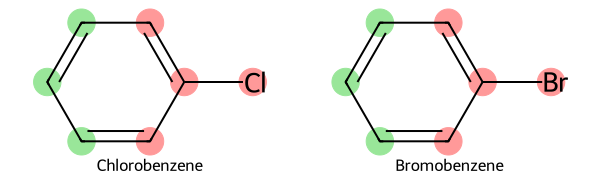

In [16]:
shared_bits = set(info_chlorobenzene) & set(info_bromobenzene)
sorted_shared_bits = sorted(shared_bits, key=lambda bit: info_chlorobenzene[bit][0][1])

colors_exercise = [shared_colors(info_chlorobenzene, sorted_shared_bits), shared_colors(info_bromobenzene, sorted_shared_bits)]

Draw.MolsToGridImage(
    [chlorobenzene, bromobenzene],
    legends=["Chlorobenzene", "Bromobenzene"],
    highlightAtomLists=[list(c) for c in colors_exercise],
    highlightAtomColors=colors_exercise,
    highlightBondLists=[[], []],
    molsPerRow=2,
    subImgSize=(300, 180),
)   

The meta and para carbons are too far (with radius = 2) for the halogen to see. Meta can see the ipso but not which atom is attached to it. Therefore, the meta environment is the same.

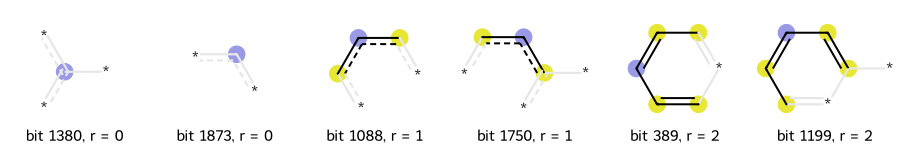

In [17]:
Draw.DrawMorganBits(
    [(chlorobenzene, bit, info_chlorobenzene) for bit in sorted_shared_bits],
    legends=[f"bit {bit}, r = {info_chlorobenzene[bit][0][1]}" for bit in sorted_shared_bits],
    molsPerRow=6,
    subImgSize=(150, 150),
)

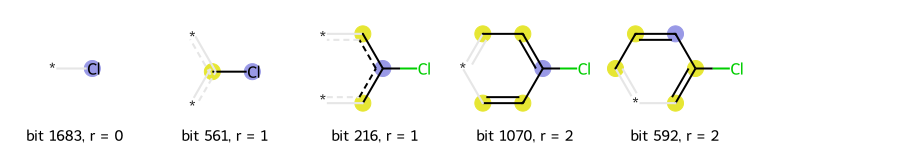

In [18]:
only_chlorobenzene = set(info_chlorobenzene) - shared_bits
sorted_only_chlorobenzene = sorted(only_chlorobenzene, key=lambda bit: info_chlorobenzene[bit][0][1])

Draw.DrawMorganBits(
    [(chlorobenzene, bit, info_chlorobenzene) for bit in sorted_only_chlorobenzene],
    legends=[f"bit {bit}, r = {info_chlorobenzene[bit][0][1]}" for bit in sorted_only_chlorobenzene],
    molsPerRow=6,
    subImgSize=(150, 150),
)

## 3. Tanimoto similarity

You computed it by hand at the end of section 2: T = c / (a + b − c), where *a* and *b* are the on-bits of each molecule and *c* the shared ones. T = 1 means identical fingerprints, T = 0 means no bit in common.

In [19]:
fp_phenol = morgan_gen.GetFingerprint(mol_by_name("Phenol"))
fp_cyclohexanol = morgan_gen.GetFingerprint(mol_by_name("Cyclohexanol"))

print(DataStructs.TanimotoSimilarity(fp_phenol, fp_cyclohexanol))

bits_a = set(fp_phenol.GetOnBits())
bits_b = set(fp_cyclohexanol.GetOnBits())
print(len(bits_a & bits_b) / len(bits_a | bits_b))     # the same, by hand

0.047619047619047616
0.047619047619047616


`&` is the set intersection and `|` the union. The two numbers agree, so `TanimotoSimilarity` is just this formula on bit vectors.

Phenol and cyclohexanol differ only in the aromatic ring, yet T is low: aromatic and aliphatic carbons are different atom types at radius 0, so almost no environment survives. Here's phenol compared with a few more compounds:

Benzene         0.27
Aniline         0.38
Chlorobenzene   0.38
p-Aminophenol   0.41
Cyclohexanol    0.05


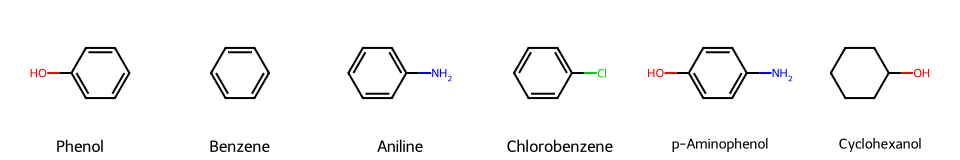

In [20]:
others = ["Benzene", "Aniline", "Chlorobenzene", "p-Aminophenol", "Cyclohexanol"]

for name in others:
    fp_other = morgan_gen.GetFingerprint(mol_by_name(name))
    print(f"{name:15s} {DataStructs.TanimotoSimilarity(fp_phenol, fp_other):.2f}")

Draw.MolsToGridImage(
    [mol_by_name(name) for name in ["Phenol"] + others],
    legends=["Phenol"] + others,
    molsPerRow=6,
    subImgSize=(160, 160),
)

- `{name:15s}` pads the name to 15 characters, so the numbers line up in a column.
- **Small molecules give low and jumpy values.** Phenol has only a few on-bits, so replacing one atom changes a large fraction of them.
- **The scale depends on the fingerprint.** For Morgan radius 2 with 2048 bits, T ≳ 0.4–0.5 is often taken as "similar" for drug-sized molecules. Other fingerprints have different typical values, so a threshold can't be carried over.
- **T = 1 doesn't mean identical molecules.** The default Morgan fingerprint ignores stereochemistry, so enantiomers and many diastereomers have T = 1.

### Exercise 3

Testosterone, progesterone and estradiol are all in ESOL.

1. Draw the three. As a chemist, which pair would you call the most similar, and which the least?
2. Compute the three pairwise Tanimoto similarities. Does the ranking match your intuition? Which structural difference costs the most bits?
3. Make generators with `radius=1` and `radius=3`, and repeat. How do the values change, and why?

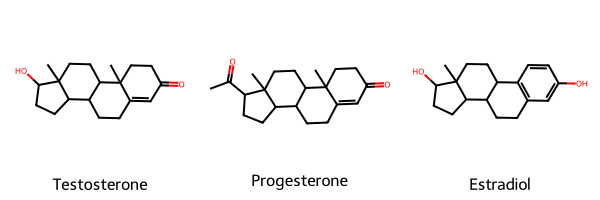

In [21]:
# Exercise 3: your code here
molecules = ["Testosterone", "Progesterone", "Estradiol"]

Draw.MolsToGridImage(
    [mol_by_name(name) for name in molecules],
    legends=["Testosterone", "Progesterone", "Estradiol"],
    molsPerRow=3,
    subImgSize=(200, 200),
)

Testosterone and progesterone are most similar because the only difference is the ketone vs. alcohol. Progesterone and estradiol are the least similar because there is an aromatic ring vs. no aromatic ring and also ketone vs. alcohol. Testosterone and estradiol both have the OH, they only differ in the ring A.

In [22]:
# Pairwise Tanimoto similarities
for i in range(len(molecules)):
    for j in range(i+1, len(molecules)):
        print(f"{molecules[i]:15s} {molecules[j]:15s} {DataStructs.TanimotoSimilarity(morgan_gen.GetFingerprint(mol_by_name(molecules[i])), morgan_gen.GetFingerprint(mol_by_name(molecules[j]))):.2f}")



Testosterone    Progesterone    0.72
Testosterone    Estradiol       0.42
Progesterone    Estradiol       0.29


I was right with my intuition. The aromatic core costs the most in bits because there are six different ring carbons (already several bits at r=0) and then every environment that contains them.

In [23]:
# Different radius
for k in [1, 2, 3]:
    morgan_gen_k = rdFingerprintGenerator.GetMorganGenerator(radius=k, fpSize=2048)
    for i in range(len(molecules)):
        for j in range(i+1, len(molecules)):
            fp_i = morgan_gen_k.GetFingerprint(mol_by_name(molecules[i]))
            fp_j = morgan_gen_k.GetFingerprint(mol_by_name(molecules[j]))
            t = DataStructs.TanimotoSimilarity(fp_i, fp_j)
            print(f"radius {k}: {molecules[i]:15s} {molecules[j]:15s} {t:.2f}")




radius 1: Testosterone    Progesterone    0.77
radius 1: Testosterone    Estradiol       0.55
radius 1: Progesterone    Estradiol       0.42
radius 2: Testosterone    Progesterone    0.72
radius 2: Testosterone    Estradiol       0.42
radius 2: Progesterone    Estradiol       0.29
radius 3: Testosterone    Progesterone    0.64
radius 3: Testosterone    Estradiol       0.32
radius 3: Progesterone    Estradiol       0.19


Every T decreases with larger radius, e.g. 0.77 -> 0.72 -> 0.64. At a larger radius, for more atoms, the environment is different. For example around the alcohol: For r=1, only the immediate neighbors see the alcohol, but for r=3 more neighbors from further away see the difference, therefore more different bits.

## 4. Similarity search

A similarity search ranks every compound in a dataset by its similarity to one query molecule. First, store a fingerprint for every compound, the same way as the `mol` column:

In [24]:
df["fp"] = df["mol"].apply(morgan_gen.GetFingerprint)

query_name = "Phenacetin"
query_fp = morgan_gen.GetFingerprint(mol_by_name(query_name))

df["sim"] = DataStructs.BulkTanimotoSimilarity(query_fp, list(df["fp"]))
print((df["sim"] > 0.4).sum())

9


- `BulkTanimotoSimilarity(fp, list_of_fps)` compares one fingerprint against a whole list and returns a list of floats in the same order. The loop runs in C++, which is much faster than calling `TanimotoSimilarity` in a Python loop.
- It needs a plain Python list, hence `list(df["fp"])`.
- Only a handful of the 1,128 compounds have T > 0.4. Most of the dataset is unrelated to phenacetin.

In [25]:
top = df[df["name"] != query_name].nlargest(6, "sim")
top[["name", "smiles", "sim", "logS"]]

,name,smiles,sim,logS
311,Dulcin,CCOc1ccc(NC(N)=O)cc1,0.709677,-2.170
915,p-Hydroxyacetanilide,CC(=O)Nc1ccc(O)cc1,0.533333,-1.030
46,p-Bromoacetanilide,CC(=O)Nc1ccc(Br)cc1,0.516129,-3.083
361,p-Fluoroacetanilide,CC(=O)Nc1ccc(F)cc1,0.516129,-1.780
878,p-Chloroacetanilide,CC(=O)Nc1ccc(Cl)cc1,0.516129,-2.843
789,Acetanilide,CC(=O)Nc1ccccc1,0.500000,-1.330


The query itself has T = 1 and is removed first. `nlargest(6, "sim")` then gives the 6 most similar compounds.

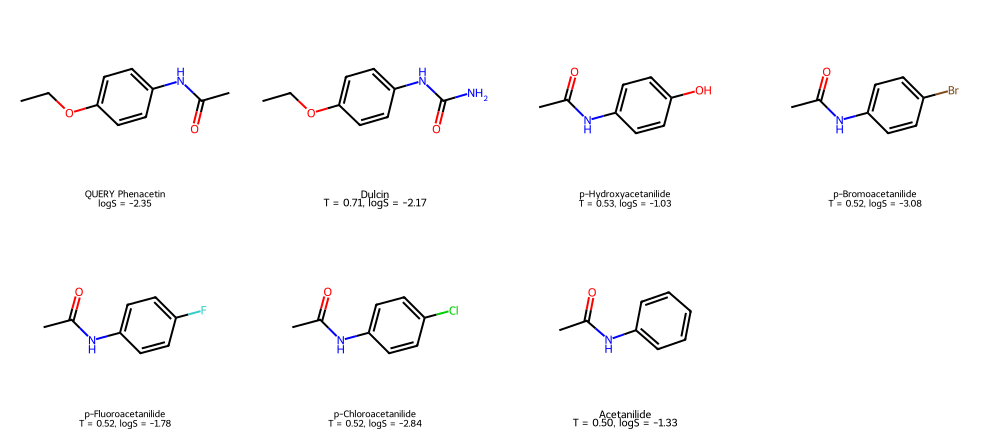

In [26]:
query_logS = df.loc[df["name"] == query_name, "logS"].iloc[0]

Draw.MolsToGridImage(
    [mol_by_name(query_name)] + list(top["mol"]),
    legends=[f"QUERY {query_name}\nlogS = {query_logS:.2f}"]
            + [f"{name}\nT = {sim:.2f}, logS = {logS:.2f}"
               for name, sim, logS in zip(top["name"], top["sim"], top["logS"])],
    molsPerRow=4,
    subImgSize=(250, 220),
)

- `\n` in a legend starts a new line.
- The nearest neighbor is dulcin, the urea analog with the same ethoxyphenyl part. The others are acetanilides, including paracetamol (listed as p-Hydroxyacetanilide). The search finds the series a medicinal chemist would make around phenacetin.
- The neighbors' logS values lie within about one log unit of the query's. This is the **similar property principle**: similar structures tend to have similar properties. Many ML models for molecules rely on it. It can fail, e.g. at an "activity cliff" where one small change has a large effect.
- Within the series, the para-halogen trend F (−1.78) → Cl (−2.84) → Br (−3.08) is what you'd expect from increasing lipophilicity. All three have the same T, because the fingerprint only sees "different halogen" bits.

### Exercise 4

1. Use **Diazepam** as the query. Find and draw its 6 most similar compounds, with T and logS in the legends.
2. How far does T drop from the 1st to the 6th neighbor? Compare with phenacetin. What does that tell you about how well ESOL covers diazepam's chemistry?
3. Are the neighbors' logS values close to diazepam's?

,name,smiles,sim_diazepam,logS
493,Nimetazepam,CN2C(=O)CN=C(c1ccccc1)c3cc(ccc23)N(=O)=O,0.666667,-3.796
248,Triazolam,Cc3nnc4CN=C(c1ccccc1Cl)c2cc(Cl)ccc2n34,0.428571,-4.090
424,Oxazepam,OC3N=C(c1ccccc1)c2cc(Cl)ccc2NC3=O,0.381818,-3.952
627,Nitrazepam,O=C3CN=C(c1ccccc1)c2cc(ccc2N3)N(=O)=O,0.344828,-3.796
77,"2,3',5-PCB",Clc1cccc(c1)c2cc(Cl)ccc2Cl,0.304348,-6.010
40,3-Chlorobiphenyl,c1c(Cl)cccc1c2ccccc2,0.302326,-4.880


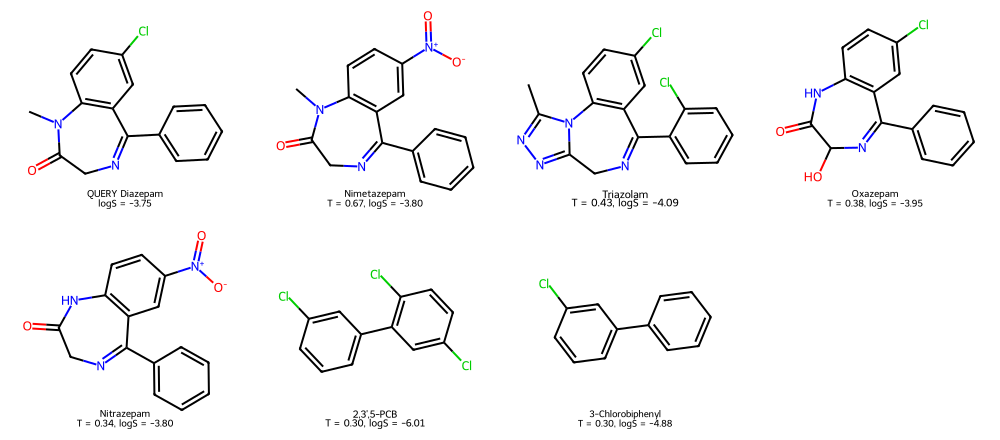

In [27]:
# Exercise 4: your code here

query_name_ex = "Diazepam"
query_fp_ex = morgan_gen.GetFingerprint(mol_by_name(query_name_ex))
df["sim_diazepam"] = DataStructs.BulkTanimotoSimilarity(query_fp_ex, list(df["fp"]))

top_ex = df[df["name"] != query_name_ex].nlargest(6, "sim_diazepam")
display(top_ex[["name", "smiles", "sim_diazepam", "logS"]])

Draw.MolsToGridImage(
    [mol_by_name(query_name_ex)] + list(top_ex["mol"]),
    legends=[f"QUERY {query_name_ex}\nlogS = {df.loc[df['name'] == query_name_ex, 'logS'].iloc[0]:.2f}"]
            + [f"{name}\nT = {sim_diazepam:.2f}, logS = {logS:.2f}"
               for name, sim_diazepam, logS in zip(top_ex["name"], top_ex["sim_diazepam"], top_ex["logS"])],
    molsPerRow=4,
    subImgSize=(250, 220),
)

From the first and sixth neighbor, the T drops from  0.67 to 0.30. If I compare it to phenacetin, the first six neighbors all contain the same core, the acetanilides. Here in this example, only the first four neighbors have the same core structure and the fifth and sixth example are only diaryls. The dataset only has a small selection of benzodiazepines.

T=0.3 means essentially nothing related left.

The logS of the diazepam-class molecules are pretty similar, only Triazolam is less soluble which might be attributed to the ortho-Cl substituent on the phenyl which adds lipophilicity. The PCBs are significantly less soluble. The similar property principle only holds for truly similar neighbors.

## Final exercise

**Predict logS from the nearest neighbors.**

1. Write a function `predict_logS(name, k=5)` that takes the name of an ESOL compound, finds its `k` most similar compounds (excluding itself), and returns the mean of their logS.
2. Run it for Atrazine, Phenacetin and Testosterone, and print the predicted and measured logS side by side.
3. For which compound does the prediction work best? Is that related to how similar its neighbors are?

This is **k-nearest-neighbors regression**, one of the simplest ML models. A later notebook builds it properly with scikit-learn.

In [53]:
# Final exercise: your code here
def predict_logS(name, k):
    query_fp = morgan_gen.GetFingerprint(mol_by_name(name))
    df["sim"] = DataStructs.BulkTanimotoSimilarity(query_fp, list(df["fp"]))
    top_k = df[df["name"] != name].nlargest(k, "sim")
    predicted_logS = top_k["logS"].mean()
    return predicted_logS

print(f"{'Molecule':<12} {'Predicted logS':>12} {'Actual logS':>12} {'Difference':>12}")
for name in ["Atrazine", "Phenacetin", "Testosterone"]:
    predicted = predict_logS(name, k=5)
    actual = df.loc[df["name"] == name, "logS"].iloc[0]
    print(f"{name:<12} {predicted:>12.2f} {actual:>12.2f} {predicted - actual:>12.2f}")

Molecule     Predicted logS  Actual logS   Difference
Atrazine            -3.58        -3.85         0.27
Phenacetin          -2.18        -2.35         0.17
Testosterone        -4.42        -4.02        -0.40


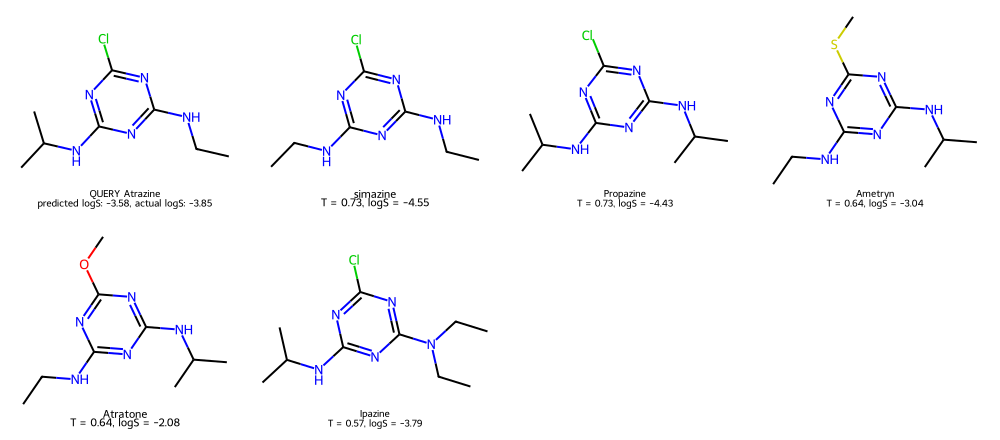

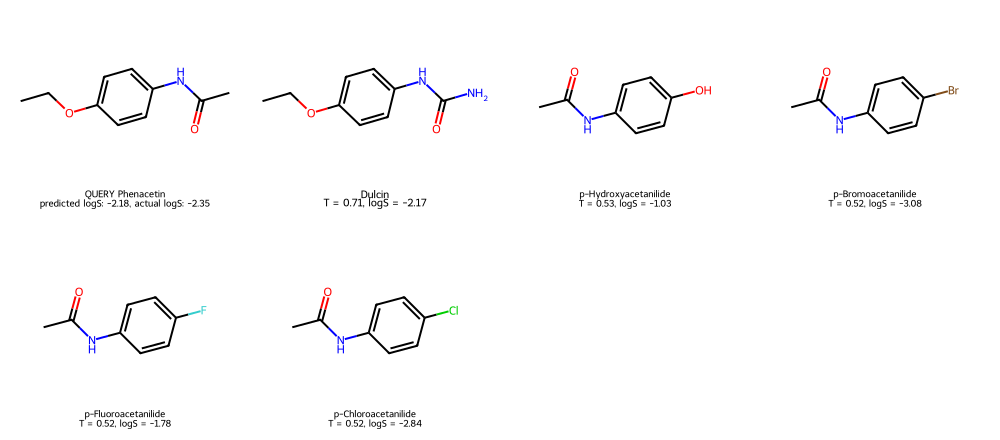

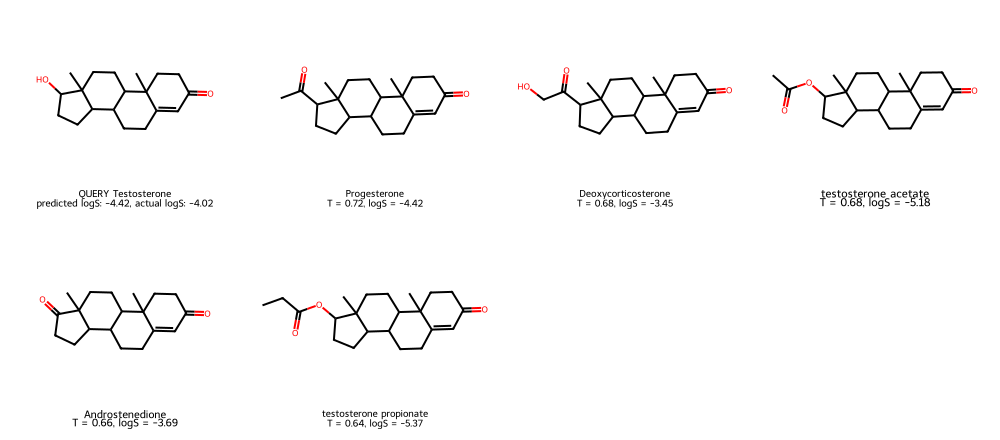

In [54]:
for i in ["Atrazine", "Phenacetin", "Testosterone"]:
    predicted = predict_logS(i, k=5)
    actual = df.loc[df["name"] == i, "logS"].iloc[0]
    top_k = df[df["name"] != i].nlargest(5, "sim")
    display(
        Draw.MolsToGridImage(
            [mol_by_name(i)] + list(top_k["mol"]),
            legends=[f"QUERY {i}\npredicted logS: {predicted:.2f}, actual logS: {actual:.2f}"]
                + [f"{name}\nT = {sim:.2f}, logS = {logS:.2f}"
                   for name, sim, logS in zip(top_k["name"], top_k  ["sim"], top_k["logS"])],
            molsPerRow=4,
            subImgSize=(250, 220),
        )   
    )

3. For which compound does the prediction work best? Is that related to how similar its neighbors are?

For phenacetin, the difference is the smallest. The similarities are smaller compared to the other examples. The number of HBD and HBA are different and therefore the logS are different too. But the difference goes in both directions, both + and -. They cancel each other out and that is why the prediction is so close.

For atrazine, the neighbors have different substituents at one positions, therefore the T value is quite high. Also, the number of HBD and HBA differ.

For testosterone, the difference is the biggest. The core of the neighbors is the same, only the C17 alcohol differs in the molecule. It's swapped for a ketone, or ester. The similarities of all neighbors is pretty high, but the logS differs significantly. Capping a free OH with an ester could lead to a drop in logS (testosterone acetate) even though the molecules are similar. 

A high T does not guarantee a similar logS because a small change in the OH group can make a big difference on the solubility (see testosterone). If the prediction is close, it does not mean that the neighbors were good because the difference can cancel each other out and accidentally lead to a good prediction (see phenacetin).
